## Supplied-data update — 4 November 2026
This notebook retains its previously executed analysis and source-access record. The subsequently uploaded BSOS CSV and codebooks are now analysed separately in **06_BSOS_Anxiety_Measurement.ipynb** and Appendix J. Earlier statements that BSOS data or empirical GAD-7 scores were unavailable are historical, not the current project status. The new file still lacks personalisation, comparison and digital-literacy variables. It is not merged with this notebook’s respondents.

# The Impact of Perceived Social Media Algorithm Personalisation on Anxiety Levels Among Generation Z: The Mediating Role of Social Comparison

## Notebook 04 Algorithm perceptions and platform comparisons
David Thulani Tinotenda Dingani · ST10358804 · RPDA8412

One additional **secondary** dataset: Taylor and Chen (2024), **Study 2** TikTok diary, [OSF project](https://osf.io/cs2aj/), [article](https://doi.org/10.1093/jcmc/zmae017). Study 1 is not added. The six original resources remain in the study.

This notebook asks whether daily algorithm responsiveness and insensitivity accompany connectedness within a person, and how worry differs across overlapping platform-user groups in the original survey. Connectedness is not anxiety; PAR/PAI are not the proposal's custom personalisation scale. This notebook does not test H1–H3 or identify the most harmful algorithm.

Upload to Google Colab using File → Upload notebook and run all cells on a CPU runtime. Restart after dependency installation if requested. Captured outputs were executed locally with IPython, not in a signed-in Colab session. Download aggregate results from `/content/research_extension/results/` after your Colab run.

The approved topic, questions and objectives remain unchanged. This notebook is a supporting secondary analysis; its measured outcomes do not replace anxiety in the research topic. See Section 1.4 and Table 4.7 of the report for the original questions and their evidential status.


## Environment

In [1]:
import sys, subprocess
from importlib.metadata import version, PackageNotFoundError
required={"numpy":"2.3.5","pandas":"2.2.3","scipy":"1.17.0","statsmodels":"0.15.0","matplotlib":"3.10.8","openpyxl":"3.1.5"}
missing=[]
for package,wanted in required.items():
    try:
        if version(package)!=wanted:missing.append(f"{package}=={wanted}")
    except PackageNotFoundError:missing.append(f"{package}=={wanted}")
if missing:subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])
print("Reference package versions:",required)


Reference package versions: {'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8', 'openpyxl': '3.1.5'}


## Acquire original files and verify checksums
Files are fetched from their public source endpoints. No participant data are transmitted outward by the analysis code. Source bytes are not embedded in this notebook. A checksum change stops the run and requires a documented source audit.

In [2]:
from pathlib import Path
import urllib.request,hashlib,zipfile,io
ROOT=Path("/content/research_extension") if Path("/content").exists() else Path.cwd()/"revision"
ROOT.mkdir(exist_ok=True,parents=True)
sources=[
 ("lonelyalgo_study2.xlsx","https://osf.io/download/qkr8s/","3370d21ad5bd6bd53e33ac21208ab2bbf1ae6479c50045cee1817edcc25de590"),
 ("codebook.xlsx","https://osf.io/download/atnk8/","285db227eb9ffdcaeba6868b275d8f440a5dc66e1389dfe8579360d562b9742d")]
for name,url,expected in sources:
    target=ROOT/name
    if not target.exists():
        try:
            with urllib.request.urlopen(url,timeout=60) as response:target.write_bytes(response.read())
        except Exception as exc:
            raise RuntimeError(f"Obtain {name} from the public OSF project https://osf.io/cs2aj/ and upload to {ROOT}, then rerun. Do not replace it with Study 1 or another file.") from exc
    assert hashlib.sha256(target.read_bytes()).hexdigest()==expected,f"Source changed: {name}; stop and audit the version."
    print("Verified",name)
# The original Ahmed sample is needed only for the platform comparison.
AHMED=ROOT.parent/"data"/"smmh.csv"
if not AHMED.exists():
    AHMED=ROOT/"ahmed"/"smmh.csv";AHMED.parent.mkdir(exist_ok=True)
if not AHMED.exists():
    try:
        url="https://www.kaggle.com/api/v1/datasets/download/souvikahmed071/social-media-and-mental-health?datasetVersionNumber=15"
        with urllib.request.urlopen(url,timeout=60) as response:archive=zipfile.ZipFile(io.BytesIO(response.read()))
        AHMED.write_bytes(archive.read("smmh.csv"))
    except Exception as exc:
        raise RuntimeError(f"Obtain original Kaggle version-15 smmh.csv and upload to {AHMED.parent}, then rerun.") from exc
assert hashlib.sha256(AHMED.read_bytes()).hexdigest()=="fd7943ecf6e9b8dbaf678556a7e9413d26509b9e9be99b59406a64a482bd3d52"
print("Original Ahmed source verified; original model split and classifiers are not changed.")


Verified lonelyalgo_study2.xlsx
Verified codebook.xlsx
Original Ahmed source verified; original model split and classifiers are not changed.


## Analysis decision record
The extension plan was recorded before these models were fitted, after the survey findings and source-paper claims were known. It is exploratory and not a public preregistration. The package includes `extension/analysis_plan.md`. No result-dependent seed, feature or threshold search is performed.

## Audit scheduled and observed data
The 4,060 rows are 290 people × 14 scheduled days. Complete-case models require at least two complete days; missing responses are not filled. Individual ages and anxiety measures are absent. No participant rows are displayed.

In [3]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
from scipy.stats import t
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from statsmodels.miscmodels.ordinal_model import OrderedModel
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

# ROOT is set by the source acquisition cell.
OUT = ROOT/'results'; OUT.mkdir(exist_ok=True)
FIG = OUT/'figures'; FIG.mkdir(exist_ok=True)
SEED = 841219
EXPECTED = '3370d21ad5bd6bd53e33ac21208ab2bbf1ae6479c50045cee1817edcc25de590'
DATA = ROOT/'lonelyalgo_study2.xlsx'
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == EXPECTED
d = pd.read_excel(DATA)
assert d.shape == (4060,11)
assert not d.duplicated(['id','day']).any()
assert d.groupby('id').day.apply(lambda x:set(x)==set(range(1,15))).all()
assert d.groupby('id').HAI.nunique().eq(1).all()
for c,lo,hi in [('connect',1,7),('par',1,7),('pai',1,7),('tkbrowse',1,5),('unusual',0,1)]:
    assert d[c].dropna().between(lo,hi).all()

core=['connect','par','pai','tkbrowse','unusual']
complete=d.dropna(subset=core).copy()
counts=complete.groupby('id').size()
q=complete[complete.id.isin(counts[counts>=2].index)].copy()
audit={'scheduled_rows':len(d),'people_in_release':d.id.nunique(),
       'connectedness_observed':int(d.connect.notna().sum()),
       'complete_core_rows_before_minimum':len(complete),
       'main_rows':len(q),'main_people':q.id.nunique(),
       'missing':d.isna().sum().to_dict(),
       'complete_days_per_person':q.groupby('id').size().describe().to_dict(),
       'sha256':EXPECTED,'seed':SEED}
missing=d.groupby('day')[core].count().reset_index()
missing['scheduled']=d.id.nunique()
missing['complete_core']=d.assign(complete=d[core].notna().all(axis=1)).groupby('day').complete.sum().values
missing.to_csv(OUT/'diary_missingness_by_day.csv',index=False)
q[core].agg(['count','mean','std','min','max']).T.to_csv(OUT/'diary_descriptives.csv')



In [4]:
# Export the source dictionary without participant records.
source_dictionary=pd.read_excel(ROOT/'codebook.xlsx',sheet_name='Sheet2')
source_dictionary.columns=['source_field','source_level','source_description']
roles={
'id':'Participant clustering key; never publish record-level identifiers',
'HAI':'Excluded; person-level awareness is not general digital literacy',
'day':'Scheduled day and exact lag key; rows may be empty',
'unusual':'Binary nuisance covariate; direction unverified',
'connect':'Supplied 1–7 connectedness outcome; not anxiety',
'esteem':'Excluded; not an anxiety proxy',
'tkbrowse':'Supplied 1–5 passive-browsing covariate; not logged exposure',
 'tkid':'Excluded; outside defined question',
'tkvalence':'Excluded; outside defined question',
'par':'Primary responsiveness predictor; not the custom personalisation scale',
'pai':'Primary insensitivity predictor; observed daily despite blank source level'}
source_dictionary['analysis_role']=source_dictionary.source_field.map(roles)
source_dictionary.to_csv(OUT/'diary_source_dictionary.csv',index=False)
print('Exported diary dictionary:',len(source_dictionary),'source fields')


Exported diary dictionary: 11 source fields


## Within-person estimator and uncertainty
Person demeaning absorbs stable participant differences. Day indicators absorb shared study-day patterns. Cluster covariance includes the degrees of freedom used by person effects. The independent-sampling unit is the participant; 2,000 participant bootstrap resamples are a sensitivity analysis. Linearity, measurement spacing, informative missingness and time-varying confounding remain limitations.

In [5]:
def within_fit(frame,outcome,predictors,label,bootstrap=0):
    z=frame.dropna(subset=[outcome]+predictors).copy()
    sizes=z.groupby('id').size();z=z[z.id.isin(sizes[sizes>=2].index)].copy()
    days=pd.get_dummies(z.day.astype('category'),prefix='day',drop_first=True,dtype=float)
    x=pd.concat([z[predictors].astype(float),days],axis=1)
    xw=x-x.groupby(z.id).transform('mean')
    yw=z[outcome]-z.groupby('id')[outcome].transform('mean')
    keep=xw.columns[xw.abs().max()>1e-12];xw=xw[keep]
    X=xw.to_numpy();Y=yw.to_numpy();N,K=X.shape
    groups,labels=np.unique(z.id.to_numpy(),return_inverse=True);G=len(groups)
    assert np.linalg.matrix_rank(X)==K
    inv=np.linalg.inv(X.T@X);beta=inv@(X.T@Y);res=Y-X@beta
    score=np.zeros((G,K));np.add.at(score,labels,X*res[:,None])
    correction=G/(G-1)*(N-1)/(N-G-K)
    cov=correction*inv@(score.T@score)@inv
    se=np.sqrt(np.diag(cov));crit=t.ppf(.975,G-1)
    p=2*t.sf(np.abs(beta/se),G-1)
    boot_ci=None
    if bootstrap:
        xx=np.stack([X[labels==g].T@X[labels==g] for g in range(G)])
        xy=np.stack([X[labels==g].T@Y[labels==g] for g in range(G)])
        rng=np.random.default_rng(SEED);est=[]
        for _ in range(bootstrap):
            weights=np.bincount(rng.integers(0,G,G),minlength=G)
            est.append(np.linalg.solve(np.einsum('g,gij->ij',weights,xx),weights@xy))
        boot_ci=np.quantile(est,[.025,.975],axis=0)
    rows=[]
    for term in predictors:
        j=list(keep).index(term)
        rows.append({'model':label,'term':term,'n_days':N,'n_people':G,'estimate':beta[j],
          'se_cluster':se[j],'ci_low':beta[j]-crit*se[j],'ci_high':beta[j]+crit*se[j],
          'p':p[j],'within_standardised':beta[j]*X[:,j].std(ddof=1)/Y.std(ddof=1),
          'bootstrap_low':None if boot_ci is None else boot_ci[0,j],
          'bootstrap_high':None if boot_ci is None else boot_ci[1,j]})
    info={'n':N,'groups':G,'predictor_columns':K,'absorbed_person_parameters':G,
          'residual_df':N-G-K,'cluster_reference_df':G-1,'condition_number':float(np.linalg.cond(X)),
          'within_r_squared':float(1-res@res/(Y@Y))}
    return pd.DataFrame(rows),info



## Fit the planned diary specifications
The two primary algorithm coefficients receive Holm correction. Primary intervals are unadjusted participant-cluster t intervals, not simultaneous intervals. Exact next-day joins cannot bridge missing days. The lag model does not adjust for previous connectedness or estimate change. Coefficients and clustered standard errors are checked against an explicit person/day dummy model.

In [6]:
main,info=within_fit(q,'connect',['par','pai','tkbrowse','unusual'],'Same day adjusted',bootstrap=2000)
primary=main.term.isin(['par','pai'])
main.loc[primary,'p_holm_primary']=multipletests(main.loc[primary,'p'],method='holm')[1]
simple,_=within_fit(q,'connect',['par','pai'],'Same day without covariates')
good_ids=q.groupby('id').size();good=q[q.id.isin(good_ids[good_ids>=7].index)]
regular,_=within_fit(good,'connect',['par','pai','tkbrowse','unusual'],'At least seven complete days')
# Join exact scheduled days. A skipped diary is never re-labelled as a next-day pair.
prev=d[['id','day','par','pai','tkbrowse']].copy();prev['day']+=1
prev=prev.rename(columns={'par':'par_previous','pai':'pai_previous','tkbrowse':'browse_previous'})
lag=d[['id','day','connect','unusual']].merge(prev,on=['id','day'],how='inner',validate='one_to_one')
lagged,laginfo=within_fit(lag,'connect',['par_previous','pai_previous','browse_previous','unusual'],'Next day association')
allfits=pd.concat([main,simple,regular,lagged],ignore_index=True)
allfits.to_csv(OUT/'diary_coefficients.csv',index=False)
audit['primary_model']=info;audit['lagged_model']=laginfo
audit['observed_lag_pairs_before_two_day_rule']=int(lag.dropna().shape[0])
# Algebraic verification against explicit person and day fixed effects.
import statsmodels.formula.api as smf
check=smf.ols('connect ~ par + pai + tkbrowse + unusual + C(day) + C(id)',data=q).fit()
assert np.allclose(main.estimate,check.params[main.term],atol=1e-9)
check_robust=check.get_robustcov_results(cov_type='cluster',groups=q.id,use_correction=True,use_t=True)
positions=[list(check.params.index).index(v) for v in main.term]
assert np.allclose(main.se_cluster,check_robust.bse[positions],rtol=1e-8)
audit['explicit_fixed_effects_check']='Coefficients and cluster standard errors agree'



<ipython-input-1-17cd92dd986b>:12: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  allfits=pd.concat([main,simple,regular,lagged],ignore_index=True)


## Explore platform membership in the retained survey
Membership groups overlap. Wilson intervals are descriptive. All three platforms enter each adjusted ordinal model, and six platform p-values across two specifications receive Holm correction. Including comparison changes the estimand and does not establish mediation. Original held-out classifiers are not refitted.

In [7]:
# Additional platform analysis of the original, unchanged Ahmed eligible sample.
AHMED=ROOT.parent/'data'/'smmh.csv'
if not AHMED.exists(): AHMED=ROOT/'ahmed'/'smmh.csv'
assert hashlib.sha256(AHMED.read_bytes()).hexdigest() == 'fd7943ecf6e9b8dbaf678556a7e9413d26509b9e9be99b59406a64a482bd3d52'
raw=pd.read_csv(AHMED)
names=['timestamp','age','gender','relationship','occupation','affiliation','uses_social','platforms','time_category','purposeless','distraction_social','restlessness','distractibility','worry','concentration','comparison','comparison_feeling','validation','low_mood','interest_fluctuation','sleep']
a=raw.copy();a.columns=names
for p in ['TikTok','Instagram','YouTube']:
    a[p]=a.platforms.str.split(',').apply(lambda v:int(p in [x.strip() for x in v]))
a=a[a.age.between(18,24)&a.age.eq(np.floor(a.age))&a.uses_social.eq('Yes')&(a[['TikTok','Instagram','YouTube']].sum(axis=1)>0)].copy()
assert len(a)==295
a['gender_group']=a.gender.str.strip().map({'Female':'Female','Male':'Male'}).fillna('Another or unspecified response')
a['student']=a.occupation.isin(['University Student','School Student']).astype(int)
des=[]
for p in ['TikTok','Instagram','YouTube']:
    for present in [1,0]:
        z=a[a[p].eq(present)];n=len(z);k=int(z.worry.ge(4).sum());ci=proportion_confint(k,n,alpha=.05,method='wilson')
        des.append({'platform':p,'uses_platform':present,'n':n,'upper_worry_n':k,'proportion':k/n,
          'wilson_low':ci[0],'wilson_high':ci[1],'mean_worry':z.worry.mean()})
pd.DataFrame(des).to_csv(OUT/'platform_descriptives.csv',index=False)
order=['More than 5 hours','Less than an Hour','Between 1 and 2 hours','Between 2 and 3 hours','Between 3 and 4 hours','Between 4 and 5 hours']
x=a[['age','student','TikTok','Instagram','YouTube']].astype(float)
x=x.join(pd.get_dummies(pd.Series(pd.Categorical(a.time_category,categories=order),index=a.index),prefix='time',drop_first=True,dtype=float))
x=x.join(pd.get_dummies(pd.Series(pd.Categorical(a.gender_group,categories=['Female','Male','Another or unspecified response']),index=a.index),prefix='gender',drop_first=True,dtype=float))
prows=[]
for add,label in [(False,'Demographics and duration'),(True,'Also conditioned on comparison')]:
    xx=x.copy()
    if add:xx['comparison']=a.comparison.astype(float)
    fit=OrderedModel(a.worry.astype(int),xx,distr='logit').fit(method='bfgs',maxiter=2000,disp=False)
    assert fit.mle_retvals['converged']
    for p in ['TikTok','Instagram','YouTube']:
        ci=fit.conf_int().loc[p]
        prows.append({'model':label,'platform':p,'or':np.exp(fit.params[p]),'ci_low':np.exp(ci.iloc[0]),'ci_high':np.exp(ci.iloc[1]),'p':fit.pvalues[p]})
pt=pd.DataFrame(prows);pt['p_holm_six']=multipletests(pt.p,method='holm')[1]
pt.to_csv(OUT/'platform_ordinal.csv',index=False)



## Export aggregate results and figures
Only aggregates are exported. The responsiveness bootstrap interval narrowly excludes zero while the primary cluster interval includes it; both must be reported. Selective use of a favourable interval is not justified. The source workbook and person identifiers are excluded from the shared package.

In [8]:
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,ax=plt.subplots(figsize=(8,4.8))
shown=allfits[((allfits.model=='Same day adjusted')&allfits.term.isin(['par','pai']))|((allfits.model=='Next day association')&allfits.term.isin(['par_previous','pai_previous']))].copy()
labels=['Same day responsiveness','Same day insensitivity','Next day responsiveness','Next day insensitivity']
for i,(_,r) in enumerate(shown.iterrows()):
    ax.errorbar(r.estimate,i,xerr=[[r.estimate-r.ci_low],[r.ci_high-r.estimate]],fmt='o',color='#245d77',capsize=4)
ax.set_yticks(range(4),labels);ax.invert_yaxis();ax.axvline(0,color='grey',ls='--',lw=1)
ax.set_xlabel('Connectedness score points per perception point (95% cluster interval)')
ax.set_title('Within-person associations on TikTok — not anxiety effects')
fig.tight_layout();fig.savefig(FIG/'05_diary_associations.png',dpi=220);plt.close(fig)
fig,ax=plt.subplots(figsize=(7,4.2))
for i,p in enumerate(['TikTok','Instagram','YouTube']):
    r=pd.DataFrame(des).query('platform==@p and uses_platform==1').iloc[0]
    ax.errorbar(100*r.proportion,i,xerr=[[100*(r.proportion-r.wilson_low)],[100*(r.wilson_high-r.proportion)]],fmt='o',capsize=4,color='#245d77')
    ax.annotate(f'n = {r.n}',(100*r.proportion,i),xytext=(8,9),textcoords='offset points',fontsize=9)
ax.set_yticks(range(3),['TikTok users','Instagram users','YouTube users']);ax.invert_yaxis();ax.set_xlim(0,100)
ax.set_xlabel('Worry score 4 or 5 (%) with Wilson 95% interval')
ax.set_title('Overlapping user groups — no causal platform ranking')
fig.tight_layout();fig.savefig(FIG/'06_platform_worry.png',dpi=220);plt.close(fig)
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(missing.day,missing.connect,marker='o',label='Connectedness recorded')
ax.plot(missing.day,missing.complete_core,marker='s',label='All core variables recorded')
ax.axhline(290,color='grey',ls='--',label='Scheduled people per day');ax.set_ylim(0,310)
ax.set_xlabel('Scheduled diary day');ax.set_ylabel('Number of records');ax.legend();fig.tight_layout()
fig.savefig(FIG/'07_diary_missingness.png',dpi=220);plt.close(fig)
(OUT/'extension_summary.json').write_text(json.dumps(audit,indent=2,default=lambda x:int(x) if isinstance(x,np.integer) else float(x)))
print(json.dumps(audit,indent=2))
print(allfits.to_string(index=False));print(pt.to_string(index=False));print(pd.DataFrame(des).to_string(index=False))


{
  "scheduled_rows": 4060,
  "people_in_release": 290,
  "connectedness_observed": 2814,
  "complete_core_rows_before_minimum": 2480,
  "main_rows": 2466,
  "main_people": 276,
  "missing": {
    "id": 0,
    "HAI": 0,
    "day": 0,
    "unusual": 1241,
    "connect": 1246,
    "esteem": 1259,
    "tkbrowse": 1249,
    "tkid": 1579,
    "tkvalence": 1679,
    "par": 1578,
    "pai": 1580
  },
  "complete_days_per_person": {
    "count": 276.0,
    "mean": 8.934782608695652,
    "std": 3.382750944507912,
    "min": 2.0,
    "25%": 6.75,
    "50%": 10.0,
    "75%": 12.0,
    "max": 14.0
  },
  "sha256": "3370d21ad5bd6bd53e33ac21208ab2bbf1ae6479c50045cee1817edcc25de590",
  "seed": 841219,
  "primary_model": {
    "n": 2466,
    "groups": 276,
    "predictor_columns": 17,
    "absorbed_person_parameters": 276,
    "residual_df": 2173,
    "cluster_reference_df": 275,
    "condition_number": 10.593846533201074,
    "within_r_squared": 0.020118705999418784
  },
  "lagged_model": {
    "n": 

## Inspect aggregate evidence

diary_descriptives.csv
diary_coefficients.csv
diary_missingness_by_day.csv
platform_descriptives.csv
platform_ordinal.csv


,Unnamed: 0,count,mean,std,min,max
0,connect,2466.0,5.2824,1.1525,1.0000,7.0
1,par,2466.0,4.5991,1.2342,1.0000,7.0
2,pai,2466.0,3.2476,1.1811,1.0000,7.0
3,tkbrowse,2466.0,3.0843,0.8164,1.3333,5.0
4,unusual,2466.0,0.0945,0.2926,0.0000,1.0


,model,term,n_days,n_people,estimate,se_cluster,ci_low,ci_high,p,within_standardised,bootstrap_low,bootstrap_high,p_holm_primary
0,Same day adjusted,par,2466,276,0.0717,0.0384,-0.0039,0.1472,0.0628,0.0548,0.0037,0.1454,0.1256
1,Same day adjusted,pai,2466,276,-0.0306,0.0289,-0.0875,0.0263,0.2903,-0.0267,-0.0841,0.0232,0.2903
2,Same day adjusted,tkbrowse,2466,276,-0.1343,0.0356,-0.2044,-0.0642,0.0002,-0.0988,-0.2015,-0.0724,NaN
3,Same day adjusted,unusual,2466,276,0.1272,0.0848,-0.0398,0.2941,0.1349,0.0420,-0.0273,0.2858,NaN
4,Same day without covariates,par,2466,276,0.0612,0.0379,-0.0135,0.1359,0.1079,0.0468,NaN,NaN,NaN
5,Same day without covariates,pai,2466,276,-0.0383,0.0289,-0.0951,0.0185,0.1852,-0.0334,NaN,NaN,NaN
6,At least seven complete days,par,2192,207,0.0705,0.0399,-0.0082,0.1491,0.0787,0.0544,NaN,NaN,NaN
7,At least seven complete days,pai,2192,207,-0.0163,0.0300,-0.0755,0.0430,0.5887,-0.0141,NaN,NaN,NaN
8,At least seven complete days,tkbrowse,2192,207,-0.1289,0.0378,-0.2034,-0.0543,0.0008,-0.0943,NaN,NaN,NaN
9,At least seven complete days,unusual,2192,207,0.1215,0.0880,-0.0521,0.2951,0.1690,0.0403,NaN,NaN,NaN


,day,connect,par,pai,tkbrowse,unusual,scheduled,complete_core
0,1,202,190,190,202,202,290,190
1,2,223,217,217,223,223,290,217
2,3,203,183,182,202,206,290,182
3,4,208,188,188,208,208,290,188
4,5,223,203,203,223,223,290,203
5,6,221,202,202,221,221,290,202
6,7,219,192,192,219,219,290,192
7,8,209,183,183,209,209,290,183
8,9,194,173,173,194,194,290,173
9,10,170,136,136,170,170,290,136


,platform,uses_platform,n,upper_worry_n,proportion,wilson_low,wilson_high,mean_worry
0,TikTok,1,72,54,0.7500,0.6391,0.8356,4.1528
1,TikTok,0,223,143,0.6413,0.5764,0.7013,3.6726
2,Instagram,1,258,181,0.7016,0.6431,0.7541,3.8721
3,Instagram,0,37,16,0.4324,0.2867,0.5909,3.2162
4,YouTube,1,272,183,0.6728,0.6150,0.7258,3.7978
5,YouTube,0,23,14,0.6087,0.4079,0.7784,3.6957


,model,platform,or,ci_low,ci_high,p,p_holm_six
0,Demographics and duration,TikTok,1.6884,1.0126,2.8151,0.0447,0.2679
1,Demographics and duration,Instagram,1.9248,0.9813,3.7754,0.0568,0.2840
2,Demographics and duration,YouTube,1.1547,0.5037,2.6471,0.7341,1.0000
3,Also conditioned on comparison,TikTok,1.2943,0.7628,2.1959,0.3389,1.0000
4,Also conditioned on comparison,Instagram,1.5734,0.8084,3.0625,0.1822,0.7289
5,Also conditioned on comparison,YouTube,0.9488,0.4045,2.2257,0.9039,1.0000


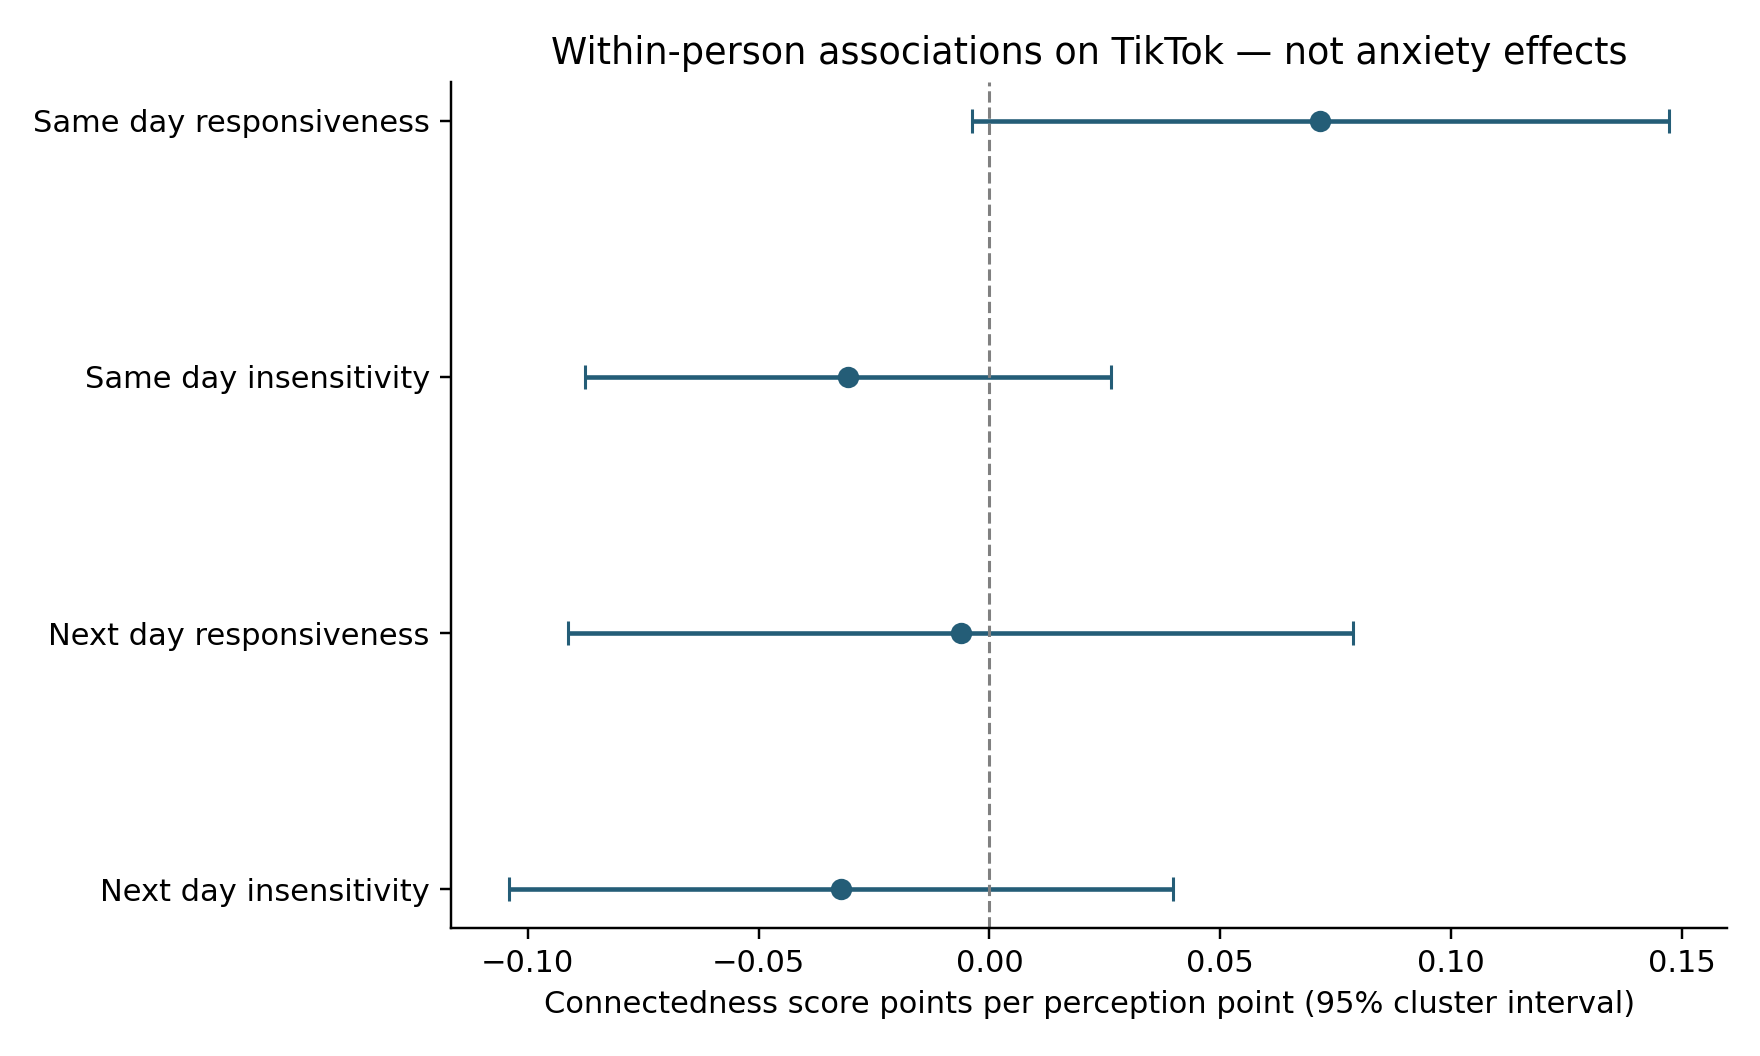

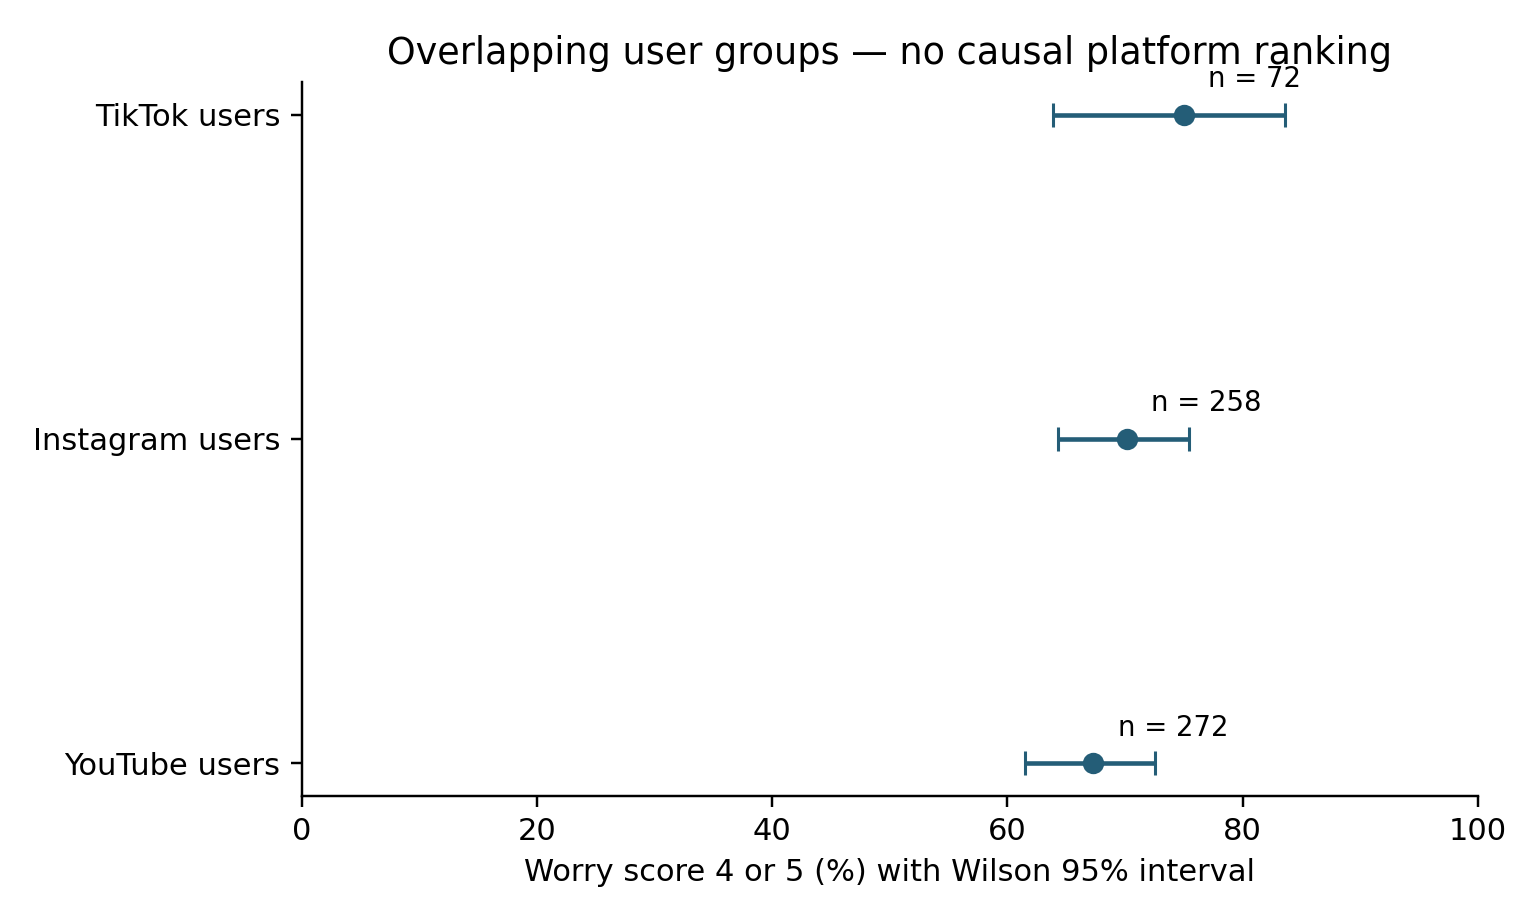

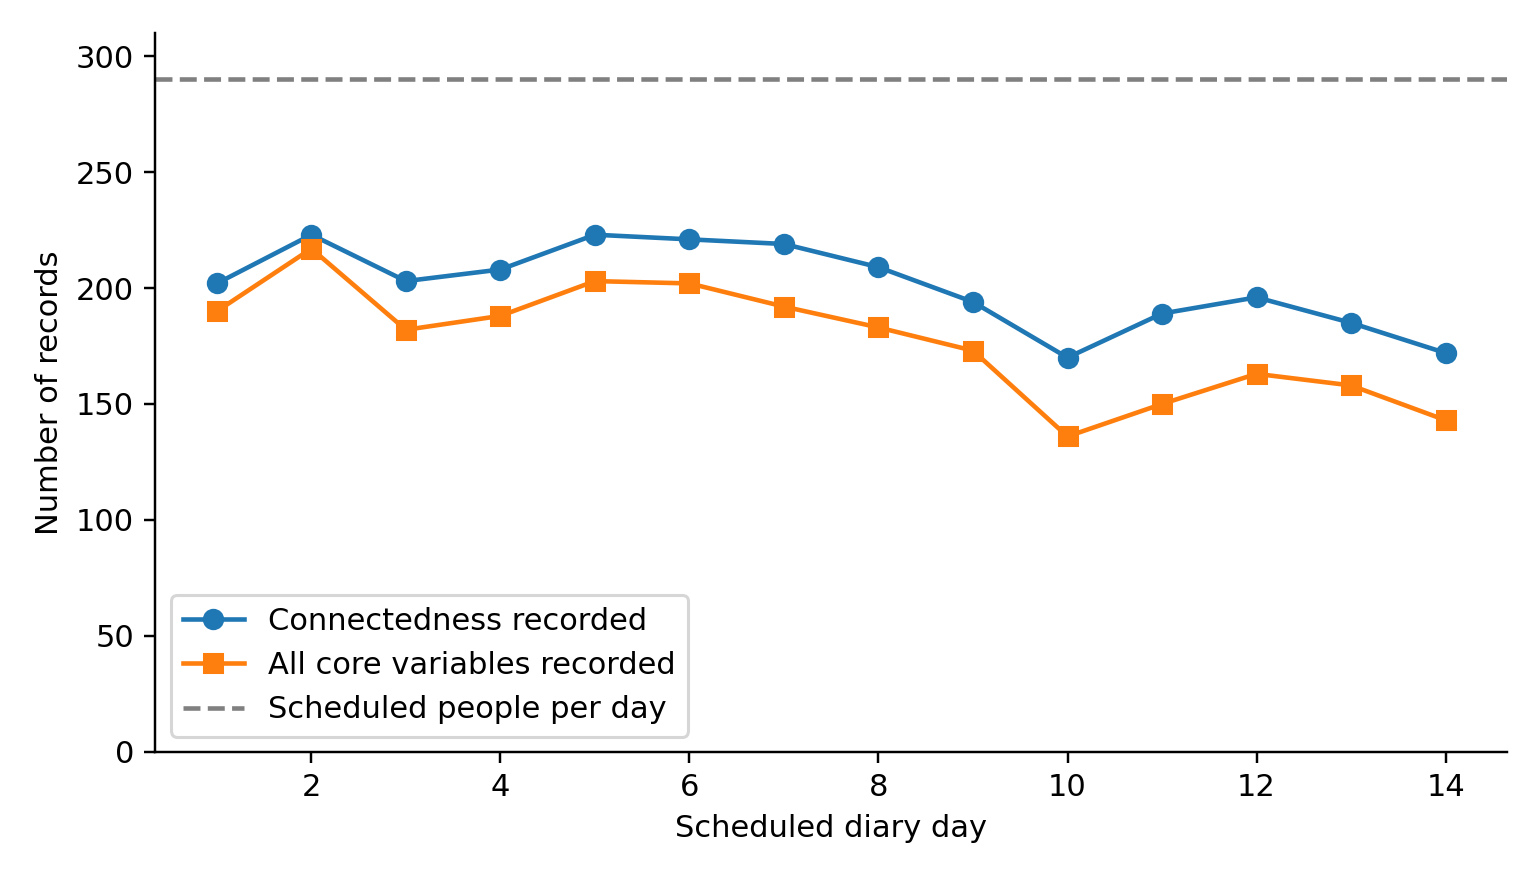

In [9]:
from IPython.display import display,Image
for name in ["diary_descriptives.csv","diary_coefficients.csv","diary_missingness_by_day.csv","platform_descriptives.csv","platform_ordinal.csv"]:
    print(name);display(pd.read_csv(OUT/name).round(4))
for name in ["05_diary_associations.png","06_platform_worry.png","07_diary_missingness.png"]:
    display(Image(filename=str(FIG/name)))


## Interpretation and limits
The diary's main PAR estimate is approximately 0.072 connectedness points per perception point; its primary interval includes zero. PAI and next-day estimates are also uncertain. The passive-browsing covariate is not an algorithm-attributable anxiety effect. TikTok users have the highest observed upper-worry proportion, but multiplicity-adjusted platform estimates do not establish a harmful-app ranking.

The diary release has no individual age field, no country field, no comparison mediator and no anxiety scale. Do not label all 290 people Generation Z or South African. Repeated scores are not 4,060 independent participants. Complete-case selection may be informative; missingness graphs and attendance sensitivity do not resolve that problem.

The public OSF metadata did not specify a licence when checked. Raw workbooks are not redistributed; obtain them from the authors' source and review applicable terms. Codebook verification is not a substitute for institutional review of an added source. Original approval/course certificates must be supplied by the researcher; none are invented.

Code prepared with AI assistance. Review, understand and disclose the assistance according to institutional requirements. The model is an exploratory reanalysis, not a replication of every claim in the original paper.
